# PyTorch 框架入门：从 Tensor 到完整训练与性能分析

根据 [《PyTorch 框架入门》](PyTorch框架入门.md) 整理的交互式学习 Notebook。

**建议方式：重启内核后，从上到下运行全部单元格。** 先阅读讲解、预测输出，再运行代码观察结果。

本 Notebook 覆盖原文全部六个主题，并将依赖上下文的代码片段串成可执行流程：

1. Tensor：创建、共享内存、形状、设备与 dtype。
2. autograd：计算图、梯度、梯度累积、手动梯度下降。
3. nn.Module：模型定义、参数、常用层与 train/eval。
4. 训练循环：Dataset/DataLoader、优化器、调度器、Checkpoint。
5. GPU：设备一致性、AMP、显存观察与峰值对比。
6. profiler：分析一个训练 step，导出时间线。

默认使用**离线生成的可学习分类数据**，无需下载数据，也可在 CPU 上完成基础实验。设置 `USE_MNIST = True` 后使用原文的 MNIST 实验；CUDA 专用实验在没有 CUDA 时会明确跳过。

合成数据的准确率不代表 MNIST 准确率。运行时生成的 Checkpoint 和 profiler trace 会写到工作目录下的 `pytorch_learning_outputs/`。


## 0. 环境准备

建议使用 Python 3.10+、PyTorch 2.3+、NumPy、Matplotlib 和 Jupyter 内核。

如果当前内核缺少依赖，可以在临时代码单元中手动执行：

```python
%pip install torch numpy matplotlib ipykernel
```

如需 CUDA，请先按 [PyTorch 官方安装选择器](https://pytorch.org/get-started/locally/) 安装与系统、驱动匹配的版本；仅安装 CPU 版 PyTorch 不会启用 GPU。

MNIST 扩展还需要与 PyTorch 匹配的 `torchvision`，例如在同一内核中执行 `%pip install torchvision`。

安装操作没有放进默认执行流程，以免“运行全部”时自动修改环境或下载大文件。


In [1]:
import gc
import math
import os
import random
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import DataLoader, Dataset, Subset
from IPython import get_ipython
from IPython.display import display

get_ipython().run_line_magic("matplotlib", "inline")
print("PyTorch:", torch.__version__)
print("CUDA runtime in PyTorch:", torch.version.cuda)
print("CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))


PyTorch: 2.5.1+cu124
CUDA runtime in PyTorch: 12.4
CUDA available: True
GPU: NVIDIA GeForce RTX 3050


下面是集中修改实验的参数。默认数据规模较小，便于在普通电脑上反复练习。

Windows/Jupyter 下先使用 `NUM_WORKERS = 0`，避免直接在 Notebook 中定义 Dataset 后，多进程启动和对象导入带来的问题。以后可在独立脚本中测试多进程数据加载。


In [2]:
SEED = 42
FORCE_CPU = False
USE_MNIST = False
TRAIN_SAMPLES = 1024
TEST_SAMPLES = 256
BATCH_SIZE = 64
NUM_EPOCHS = 5
LEARNING_RATE = 3e-3
HIDDEN_DIM = 64
NUM_WORKERS = 0

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# 小型 CPU 实验限制线程数，避免过多线程的调度开销。
torch.set_num_threads(min(4, os.cpu_count() or 1))
DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() and not FORCE_CPU else "cpu"
)
OUTPUT_DIR = Path("pytorch_learning_outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print("Device:", DEVICE)
print("Output directory:", OUTPUT_DIR)


Device: cuda
Output directory: pytorch_learning_outputs


## 1. Tensor：数据、形状、内存和设备

Tensor 是携带 shape、dtype、device 等信息的多维数组。后续模型参数、输入、梯度都以 Tensor 形式表示。

先观察各种创建方式，不急着记住所有 API。


In [3]:
tensor_examples = {
    "from_list": torch.tensor([1.0, 2.0, 3.0]),
    "zeros": torch.zeros(3, 4),
    "ones": torch.ones(2, 3, 4),
    "normal": torch.randn(3, 4),
    "arange": torch.arange(0, 10, 2),
}
tensor_examples["zeros_like"] = torch.zeros_like(tensor_examples["normal"])
for name, tensor in tensor_examples.items():
    print(f"{name:12s} shape={tuple(tensor.shape)!s:12s} "
          f"dtype={str(tensor.dtype):14s} device={tensor.device}")
assert tensor_examples["arange"].tolist() == [0, 2, 4, 6, 8]


from_list    shape=(3,)         dtype=torch.float32  device=cpu
zeros        shape=(3, 4)       dtype=torch.float32  device=cpu
ones         shape=(2, 3, 4)    dtype=torch.float32  device=cpu
normal       shape=(3, 4)       dtype=torch.float32  device=cpu
arange       shape=(5,)         dtype=torch.int64    device=cpu
zeros_like   shape=(3, 4)       dtype=torch.float32  device=cpu


### 1.1 NumPy 与 Tensor：共享还是拷贝？

对支持的 CPU NumPy 数组，`torch.from_numpy` 与原数组共享底层内存；`torch.tensor(array)` 则创建拷贝。它和前面学过的“多个名字引用同一个对象”不同：这里是两个不同类型的对象共享存储。


In [4]:
numpy_array = np.array([1.0, 2.0, 3.0], dtype=np.float32)
shared_tensor = torch.from_numpy(numpy_array)
copied_tensor = torch.tensor(numpy_array)

numpy_array[0] = 100.0
shared_tensor[1] = 200.0
print("NumPy:", numpy_array)
print("Shared:", shared_tensor)
print("Copied:", copied_tensor)
assert numpy_array.tolist() == [100.0, 200.0, 3.0]
assert copied_tensor.tolist() == [1.0, 2.0, 3.0]


NumPy: [100. 200.   3.]
Shared: tensor([100., 200.,   3.])
Copied: tensor([1., 2., 3.])


### 1.2 view、reshape 与内存连续性

`view` 要求目标形状与现有 stride 兼容，并非所有情形都必须完全连续；下面的转置例子不能直接展平为 view。

`reshape` 在可能时返回视图，否则复制数据；因此不能仅从函数名判断是否发生拷贝。`permute/transpose` 通常只调整视图的 shape/stride。


In [5]:
original = torch.arange(12)
matrix = original.view(3, 4)
transposed = matrix.transpose(0, 1)
print("Matrix:\n", matrix)
print("Transposed:\n", transposed)
print("Contiguous:", matrix.is_contiguous(), transposed.is_contiguous())
print("Strides:", matrix.stride(), transposed.stride())

try:
    transposed.view(-1)
except RuntimeError:
    print("Expected: this transposed tensor cannot be flattened with view.")

reshaped_copy = transposed.reshape(-1)
explicit_copy = transposed.contiguous().view(-1)
assert torch.equal(reshaped_copy, explicit_copy)
reshaped_copy[0] = -99
assert matrix[0, 0].item() == 0
print("reshape created an independent buffer in this example.")


Matrix:
 tensor([[ 0,  1,  2,  3],
        [ 4,  5,  6,  7],
        [ 8,  9, 10, 11]])
Transposed:
 tensor([[ 0,  4,  8],
        [ 1,  5,  9],
        [ 2,  6, 10],
        [ 3,  7, 11]])
Contiguous: True False
Strides: (4, 1) (1, 4)
Expected: this transposed tensor cannot be flattened with view.
reshape created an independent buffer in this example.


In [6]:
tokens = torch.randn(2, 8, 3, 4)           # B, N, H, D
heads = tokens.permute(0, 2, 1, 3)        # B, H, N, D
merged = heads.transpose(1, 2).contiguous().view(2, 8, 12)
print("Before split:", tokens.shape)
print("Per head:", heads.shape)
print("Merged:", merged.shape)
assert torch.equal(merged, tokens.reshape(2, 8, 12))

singleton = torch.randn(1, 3, 1, 4)
print("squeeze:", singleton.squeeze().shape)
print("unsqueeze:", torch.randn(3, 4).unsqueeze(0).shape)


Before split: torch.Size([2, 8, 3, 4])
Per head: torch.Size([2, 3, 8, 4])
Merged: torch.Size([2, 8, 12])
squeeze: torch.Size([3, 4])
unsqueeze: torch.Size([1, 3, 4])


上面的形状变换对应 MHA 中的拆头、合头。`squeeze()` 会去掉所有长度为 1 的维度；如果 batch size 可能为 1，使用 `squeeze(dim)` 明确指定维度更容易控制结果。

### 1.3 设备和 dtype

模型与输入必须在同一设备，输入类型也应符合算子要求。CPU–GPU 搬运通常经过主机与设备互联，其带宽低于 GPU 本地显存带宽；小数据反复搬运也会产生调度开销。


In [7]:
cpu_tensor = torch.randn(3, 4)
device_tensor = cpu_tensor.to(DEVICE)
round_trip = device_tensor.cpu()
direct_tensor = torch.randn(3, 4, device=DEVICE)
print("CPU -> selected device -> CPU:",
      cpu_tensor.device, device_tensor.device, round_trip.device)
print("Created directly on:", direct_tensor.device)
torch.testing.assert_close(cpu_tensor, round_trip)


CPU -> selected device -> CPU: cpu cuda:0 cpu
Created directly on: cuda:0


In [8]:
for dtype in [torch.float32, torch.float16, torch.bfloat16]:
    precision_tensor = torch.zeros(1000, 1000, dtype=dtype)
    size_mib = precision_tensor.numel() * precision_tensor.element_size() / 1024**2
    print(f"{str(dtype):16s} bytes/element={precision_tensor.element_size()} "
          f"storage={size_mib:.2f} MiB")
assert torch.tensor(0, dtype=torch.float32).element_size() == 4
assert torch.tensor(0, dtype=torch.bfloat16).element_size() == 2


torch.float32    bytes/element=4 storage=3.81 MiB
torch.float16    bytes/element=2 storage=1.91 MiB
torch.bfloat16   bytes/element=2 storage=1.91 MiB


FP16 和 BF16 都是 2 字节。BF16 的指数位与 FP32 相同，动态范围接近 FP32，但有效数字精度更低。实际速度取决于硬件和算子；dtype 字节减半不代表训练总显存或运行时间必然减半。

**停下来想一想：** `reshape` 是否一定复制？把一个 Tensor 搬到 GPU 后，原来的 NumPy 数组还能共享这份 GPU 存储吗？


## 2. autograd：从计算图到手动训练

前向运算动态记录依赖关系，反向传播根据链式法则计算梯度。通常只有 requires_grad 的叶节点会自动把梯度保存到 `.grad`；非叶节点可通过 `retain_grad()` 请求保存。


In [9]:
grad_input = torch.tensor([2.0, 3.0], requires_grad=True)
intermediate = grad_input * 3
intermediate.retain_grad()
scalar_output = intermediate.sum()
scalar_output.backward()

print("Output:", scalar_output.item())
print("Leaf / non-leaf:", grad_input.is_leaf, intermediate.is_leaf)
print("Input gradient:", grad_input.grad)
print("Retained intermediate gradient:", intermediate.grad)
torch.testing.assert_close(grad_input.grad, torch.tensor([3.0, 3.0]))
torch.testing.assert_close(intermediate.grad, torch.ones(2))


Output: 15.0
Leaf / non-leaf: True False
Input gradient: 

tensor([3., 3.])
Retained intermediate gradient: tensor([1., 1.])


### 2.1 非标量也能 backward

原文中“只能对标量调用 backward”需要加上条件：**只有省略 `gradient` 参数时，输出才需要是单元素张量。** 对非标量输出，可以提供匹配的上游梯度，计算向量–雅可比积。


In [10]:
vector_input = torch.tensor([2.0, 3.0], requires_grad=True)
vector_output = vector_input.square()
vector_output.backward(gradient=torch.ones_like(vector_output))
print("Gradient of sum(x**2):", vector_input.grad)
torch.testing.assert_close(vector_input.grad, torch.tensor([4.0, 6.0]))


Gradient of sum(x**2): tensor([4., 6.])


### 2.2 梯度默认累加；每次前向通常建立新图

下面的三次 backward 来自三个新建的前向图，不需要 `retain_graph=True`。同一计算图反向后，中间保存的数据通常会释放；保留图并不是普通训练循环的默认需求。


In [11]:
accumulated = torch.tensor([1.0], requires_grad=True)
(accumulated * 2).sum().backward()
print("First:", accumulated.grad)
(accumulated * 3).sum().backward()
print("Accumulated:", accumulated.grad)
torch.testing.assert_close(accumulated.grad, torch.tensor([5.0]))

accumulated.grad.zero_()
(accumulated * 4).sum().backward()
print("After zeroing:", accumulated.grad)
torch.testing.assert_close(accumulated.grad, torch.tensor([4.0]))


First: tensor([2.])
Accumulated: tensor([5.])
After zeroing: tensor([4.])


### 2.3 no_grad、detach 和拷贝

`no_grad` 控制作用域内运算是否记录梯度；`detach` 返回脱离当前梯度图的张量，但通常仍共享底层存储。需要独立数据时，使用 `detach().clone()`。


In [12]:
tracked = torch.tensor([1.0, 2.0], requires_grad=True)
with torch.no_grad():
    untracked_result = tracked * 2
detached_view = tracked.detach()
independent_snapshot = tracked.detach().clone()
print("Requires grad:", tracked.requires_grad, untracked_result.requires_grad)
print("detach shares storage:", tracked.data_ptr() == detached_view.data_ptr())
assert not untracked_result.requires_grad
assert independent_snapshot.data_ptr() != tracked.data_ptr()


Requires grad: True False
detach shares storage: True


### 2.4 手动梯度下降：学习 y = 2x + 1

每轮执行：计算预测与 loss → backward → 在 no_grad 下更新参数 → 清零梯度。这里使用中心化输入和足够迭代，避免把尚未收敛的结果误写成精确的 2 和 1。


Learned: y = 2.0000x + 1.0000


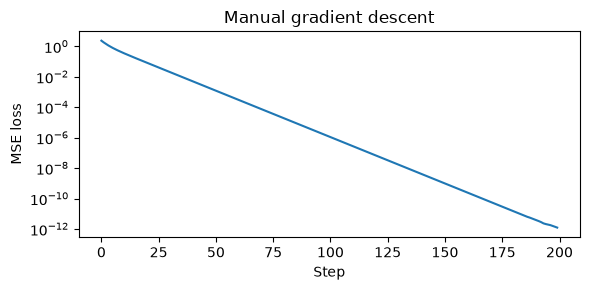

In [13]:
regression_x = torch.linspace(-1, 1, 128)
regression_y = 2 * regression_x + 1
learned_w = torch.tensor(0.0, requires_grad=True)
learned_b = torch.tensor(0.0, requires_grad=True)
regression_losses = []

for _ in range(200):
    regression_loss = ((learned_w * regression_x + learned_b - regression_y) ** 2).mean()
    regression_loss.backward()
    with torch.no_grad():
        learned_w -= 0.1 * learned_w.grad
        learned_b -= 0.1 * learned_b.grad
    learned_w.grad.zero_()
    learned_b.grad.zero_()
    regression_losses.append(regression_loss.item())

print(f"Learned: y = {learned_w.item():.4f}x + {learned_b.item():.4f}")
assert abs(learned_w.item() - 2) < 0.01
assert abs(learned_b.item() - 1) < 0.01
plt.figure(figsize=(6, 3))
plt.semilogy(regression_losses)
plt.xlabel("Step")
plt.ylabel("MSE loss")
plt.title("Manual gradient descent")
plt.tight_layout()
plt.show()


## 3. nn.Module：组织模型与参数

自定义模型继承 `nn.Module`，在 `__init__` 中注册层，在 `forward` 中描述计算。调用 `model(x)`，让 Module 的调用逻辑和 hooks 正常工作。


In [14]:
class TwoLayerMLP(nn.Module):
    def __init__(self, input_dim=784, hidden_dim=256, output_dim=10, dropout=0.1):
        super().__init__()
        self.flatten = nn.Flatten(start_dim=1)
        self.fc1 = nn.Linear(input_dim, hidden_dim)
        self.relu = nn.ReLU()
        self.dropout = nn.Dropout(dropout)
        self.fc2 = nn.Linear(hidden_dim, output_dim)

    def forward(self, inputs):
        inputs = self.flatten(inputs)
        return self.fc2(self.dropout(self.relu(self.fc1(inputs))))

module_demo = TwoLayerMLP()
module_output = module_demo(torch.randn(32, 784))
parameter_count = sum(parameter.numel() for parameter in module_demo.parameters())
print(module_demo)
print("Output:", module_output.shape)
print("Parameters:", f"{parameter_count:,}")
assert module_output.shape == (32, 10)
assert parameter_count == 203_530


TwoLayerMLP(
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (fc1): Linear(in_features=784, out_features=256, bias=True)
  (relu): ReLU()
  (dropout): Dropout(p=0.1, inplace=False)
  (fc2): Linear(in_features=256, out_features=10, bias=True)
)
Output: torch.Size([32, 10])
Parameters: 203,530


In [15]:
for name, parameter in module_demo.named_parameters():
    print(f"{name:12s} shape={str(tuple(parameter.shape)):12s} "
          f"trainable={parameter.requires_grad}")
print("state_dict keys:", list(module_demo.state_dict()))
linear_demo = nn.Linear(10, 5)
assert sum(parameter.numel() for parameter in linear_demo.parameters()) == 55


fc1.weight   shape=(256, 784)   trainable=True
fc1.bias     shape=(256,)       trainable=True
fc2.weight   shape=(10, 256)    trainable=True
fc2.bias     shape=(10,)        trainable=True
state_dict keys: ['fc1.weight', 'fc1.bias', 'fc2.weight', 'fc2.bias']


`parameters()` 提供可训练参数；`state_dict()` 还可以包含持久化 buffer，例如 BatchNorm 统计量，所以两者不完全相同。

下面缩小 Embedding 的词表以控制教学实验的内存；它仍然展示“token ID → 稠密向量”的过程。


In [16]:
embedding_layer = nn.Embedding(num_embeddings=1000, embedding_dim=32)
token_ids = torch.tensor([0, 42], dtype=torch.long)
embedded = embedding_layer(token_ids)
normalized = nn.LayerNorm(32)(embedded)
print("Embedding:", embedded.shape)
print("LayerNorm row means:", normalized.mean(dim=-1).detach())
assert embedded.shape == (2, 32)
torch.testing.assert_close(
    normalized.mean(dim=-1), torch.zeros(2), atol=1e-5, rtol=0
)


Embedding: torch.Size([2, 32])
LayerNorm row means: tensor([2.9802e-08, 7.4506e-09])


### train/eval 与梯度开关是两件事

`train() / eval()` 改变 Dropout、BatchNorm 等层的行为。`no_grad / inference_mode` 控制梯度记录。调用 `eval()` 本身不会关闭 autograd。


In [17]:
dropout_demo = nn.Dropout(p=0.5)
all_ones = torch.ones(20)
dropout_demo.train()
training_values = dropout_demo(all_ones)
dropout_demo.eval()
evaluation_values = dropout_demo(all_ones)
print("Dropout training:", training_values)
print("Dropout evaluation:", evaluation_values)
assert torch.equal(evaluation_values, all_ones)

module_demo.eval()
evaluation_with_graph = module_demo(torch.randn(2, 784))
with torch.inference_mode():
    evaluation_without_graph = module_demo(torch.randn(2, 784))
print("eval() still records grad:", evaluation_with_graph.requires_grad)
print("inference_mode records grad:", evaluation_without_graph.requires_grad)
assert evaluation_with_graph.requires_grad
assert not evaluation_without_graph.requires_grad


Dropout training: tensor([0., 2., 0., 0., 0., 2., 2., 2., 0., 2., 2., 2., 2., 2., 0., 0., 0., 0.,
        2., 2.])
Dropout evaluation: tensor([1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
        1., 1.])
eval() still records grad: True
inference_mode records grad: False


## 4. 完整训练循环：从数据到 Checkpoint

原文使用 MNIST。这里保留相同的 28×28 输入、10 类分类任务和 MLP 训练流程：

- 默认：共享类别原型加噪声构造的离线合成数据，便于 CPU 快速学习流程。
- `USE_MNIST = True`：下载真实 MNIST，并按配置取子集；增大 `TRAIN_SAMPLES / TEST_SAMPLES` 可使用更多样本。

Dataset 定义一条样本如何读取，DataLoader 负责打乱、组批等。


In [18]:
class SimpleDataset(Dataset):
    def __init__(self, data, labels):
        if len(data) != len(labels):
            raise ValueError("Data and labels must have the same length.")
        self.data = data
        self.labels = labels

    def __len__(self):
        return len(self.data)

    def __getitem__(self, index):
        return self.data[index], self.labels[index]

if USE_MNIST:
    from torchvision import datasets, transforms

    image_transform = transforms.Compose([
        transforms.ToTensor(),
        transforms.Normalize((0.1307,), (0.3081,)),
    ])
    full_train_set = datasets.MNIST(
        OUTPUT_DIR / "data", train=True, download=True, transform=image_transform
    )
    full_test_set = datasets.MNIST(
        OUTPUT_DIR / "data", train=False, download=True, transform=image_transform
    )
    train_set = Subset(full_train_set, range(min(TRAIN_SAMPLES, len(full_train_set))))
    test_set = Subset(full_test_set, range(min(TEST_SAMPLES, len(full_test_set))))
    dataset_name = "MNIST subset"
else:
    prototype_generator = torch.Generator().manual_seed(SEED)
    prototypes = torch.randn(10, 1, 28, 28, generator=prototype_generator) * 0.5

    def make_synthetic_dataset(size, seed):
        generator = torch.Generator().manual_seed(seed)
        labels = torch.randint(0, 10, (size,), generator=generator)
        noise = torch.randn(size, 1, 28, 28, generator=generator) * 0.35
        return SimpleDataset(prototypes[labels] + noise, labels)

    train_set = make_synthetic_dataset(TRAIN_SAMPLES, SEED + 1)
    test_set = make_synthetic_dataset(TEST_SAMPLES, SEED + 2)
    dataset_name = "Offline synthetic data (not MNIST)"

print("Dataset:", dataset_name)
print("Train / validation samples:", len(train_set), len(test_set))


Dataset: Offline synthetic data (not MNIST)
Train / validation samples: 1024 256


Batch images: torch.Size([64, 1, 28, 28]) torch.float32
Batch labels: torch.Size([64]) torch.int64


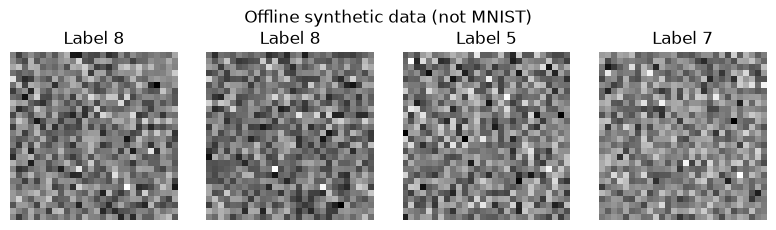

In [19]:
train_loader = DataLoader(
    train_set, batch_size=BATCH_SIZE, shuffle=True,
    num_workers=NUM_WORKERS, pin_memory=DEVICE.type == "cuda",
    generator=torch.Generator().manual_seed(SEED),
)
test_loader = DataLoader(
    test_set, batch_size=BATCH_SIZE, shuffle=False,
    num_workers=NUM_WORKERS, pin_memory=DEVICE.type == "cuda",
)
sample_images, sample_labels = next(iter(train_loader))
print("Batch images:", sample_images.shape, sample_images.dtype)
print("Batch labels:", sample_labels.shape, sample_labels.dtype)
assert sample_images.shape[1:] == (1, 28, 28)
assert sample_labels.dtype == torch.long

fig, axes = plt.subplots(1, 4, figsize=(8, 2.3))
for index, axis in enumerate(axes):
    image, label = train_set[index]
    axis.imshow(image.squeeze().numpy(), cmap="gray")
    axis.set_title(f"Label {int(label)}")
    axis.axis("off")
fig.suptitle(dataset_name)
plt.tight_layout()
plt.show()


`pin_memory=True` 配合适当的 `non_blocking=True` 传输，有助于异步主机到设备拷贝；真正与计算重叠还取决于 stream、数据准备等条件，并非打开一个开关就一定提速。

### 4.1 每个训练 step 的五步

1. `optimizer.zero_grad(set_to_none=True)`：清除上一次更新的梯度。
2. `model(inputs)`：前向计算 logits。
3. `criterion(logits, labels)`：计算 loss。
4. `loss.backward()`：反向计算梯度。
5. `optimizer.step()`：更新参数。

有意进行梯度累积时，不在每个 micro-batch 前清零。`CrossEntropyLoss` 接收原始 logits 和整型类别标签，模型末尾不需要先做 Softmax。

下面按样本数加权平均 loss，并在设备端累积指标，每轮末尾才提取标量，避免 GPU 上每个 batch 都调用 `item()`。


In [20]:
def train_one_epoch(model, loader, optimizer, criterion, device):
    model.train()
    loss_sum = torch.zeros((), device=device)
    correct = torch.zeros((), dtype=torch.long, device=device)
    count = 0
    for images, labels in loader:
        images = images.to(device, non_blocking=device.type == "cuda")
        labels = labels.to(device, non_blocking=device.type == "cuda")
        optimizer.zero_grad(set_to_none=True)
        logits = model(images)
        loss = criterion(logits, labels)
        loss.backward()
        optimizer.step()
        loss_sum += loss.detach() * labels.numel()
        correct += (logits.detach().argmax(dim=1) == labels).sum()
        count += labels.numel()
    return loss_sum.item() / count, correct.item() / count

@torch.no_grad()
def evaluate(model, loader, criterion, device):
    model.eval()
    loss_sum = torch.zeros((), device=device)
    correct = torch.zeros((), dtype=torch.long, device=device)
    count = 0
    for images, labels in loader:
        images = images.to(device, non_blocking=device.type == "cuda")
        labels = labels.to(device, non_blocking=device.type == "cuda")
        logits = model(images)
        loss_sum += criterion(logits, labels) * labels.numel()
        correct += (logits.argmax(dim=1) == labels).sum()
        count += labels.numel()
    return loss_sum.item() / count, correct.item() / count


In [21]:
torch.manual_seed(SEED)
model_config = {
    "input_dim": 784, "hidden_dim": HIDDEN_DIM,
    "output_dim": 10, "dropout": 0.1,
}
trained_model = TwoLayerMLP(**model_config).to(DEVICE)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(trained_model.parameters(), lr=LEARNING_RATE)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer, T_max=NUM_EPOCHS
)
history = []

for epoch in range(NUM_EPOCHS):
    current_lr = optimizer.param_groups[0]["lr"]
    train_loss, train_accuracy = train_one_epoch(
        trained_model, train_loader, optimizer, criterion, DEVICE
    )
    validation_loss, validation_accuracy = evaluate(
        trained_model, test_loader, criterion, DEVICE
    )
    history.append({
        "epoch": epoch + 1, "lr": current_lr,
        "train_loss": train_loss, "train_accuracy": train_accuracy,
        "validation_loss": validation_loss,
        "validation_accuracy": validation_accuracy,
    })
    scheduler.step()
    print(f"Epoch {epoch+1}/{NUM_EPOCHS} | "
          f"loss {train_loss:.4f}/{validation_loss:.4f} | "
          f"accuracy {train_accuracy:.1%}/{validation_accuracy:.1%} | "
          f"lr {current_lr:.6f}")

assert all(math.isfinite(row["train_loss"]) for row in history)


Epoch 1/5 | loss 0.4640/0.0003 | accuracy 93.6%/100.0% | lr 0.003000
Epoch 2/5 | loss 0.0002/0.0000 | accuracy 100.0%/100.0% | lr 0.002714
Epoch 3/5 | loss 0.0001/0.0000 | accuracy 100.0%/100.0% | lr 0.001964
Epoch 4/5 | loss 0.0000/0.0000 | accuracy 100.0%/100.0% | lr 0.001036
Epoch 5/5 | loss 0.0000/0.0000 | accuracy 100.0%/100.0% | lr 0.000286


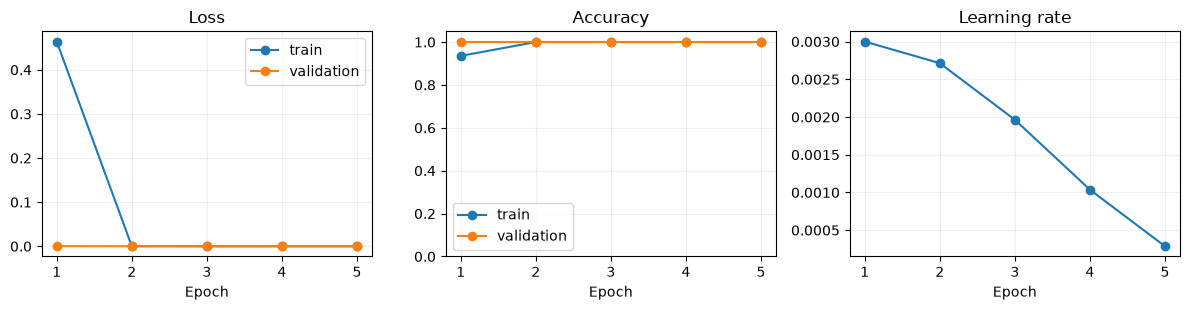

In [22]:
epochs = [row["epoch"] for row in history]
fig, axes = plt.subplots(1, 3, figsize=(12, 3.2))
axes[0].plot(epochs, [row["train_loss"] for row in history], "o-", label="train")
axes[0].plot(epochs, [row["validation_loss"] for row in history], "o-", label="validation")
axes[0].set_title("Loss")
axes[1].plot(epochs, [row["train_accuracy"] for row in history], "o-", label="train")
axes[1].plot(epochs, [row["validation_accuracy"] for row in history], "o-", label="validation")
axes[1].set_title("Accuracy")
axes[1].set_ylim(0, 1.05)
axes[2].plot(epochs, [row["lr"] for row in history], "o-")
axes[2].set_title("Learning rate")
for axis in axes:
    axis.set_xlabel("Epoch")
    axis.grid(alpha=0.2)
axes[0].legend()
axes[1].legend()
plt.tight_layout()
plt.show()


### 4.2 保存、恢复和校验 Checkpoint

推理通常只需要模型权重；恢复训练还需要优化器、调度器、轮次等状态。这里保存纯字典、张量和基本数据，使用 `weights_only=True` 加载。

本实验验证恢复后的输出一致，并继续训练一轮。若要求断点前后逐步完全复现，还要管理随机数、采样器和数据迭代进度等状态。


In [23]:
checkpoint_path = OUTPUT_DIR / "checkpoint.pt"
torch.save({
    "epoch": len(history),
    "model_config": model_config,
    "model_state_dict": trained_model.state_dict(),
    "optimizer_state_dict": optimizer.state_dict(),
    "scheduler_state_dict": scheduler.state_dict(),
    "history": history,
}, checkpoint_path)

checkpoint = torch.load(
    checkpoint_path, map_location=DEVICE, weights_only=True
)
restored_model = TwoLayerMLP(**checkpoint["model_config"]).to(DEVICE)
restored_optimizer = torch.optim.AdamW(
    restored_model.parameters(), lr=LEARNING_RATE
)
restored_scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    restored_optimizer, T_max=NUM_EPOCHS
)
restored_model.load_state_dict(checkpoint["model_state_dict"])
restored_optimizer.load_state_dict(checkpoint["optimizer_state_dict"])
restored_scheduler.load_state_dict(checkpoint["scheduler_state_dict"])

trained_model.eval()
restored_model.eval()
with torch.no_grad():
    comparison_inputs = sample_images[:8].to(DEVICE)
    expected_logits = trained_model(comparison_inputs)
    restored_logits = restored_model(comparison_inputs)
torch.testing.assert_close(expected_logits, restored_logits)
assert restored_optimizer.state
assert restored_scheduler.state_dict() == scheduler.state_dict()
print("Saved:", checkpoint_path)
print("Restored epoch:", checkpoint["epoch"])
print("Checkpoint output check: passed")


Saved: pytorch_learning_outputs\checkpoint.pt
Restored epoch: 5
Checkpoint output check: passed


原计划的余弦调度已经走完全部 `NUM_EPOCHS`。下面明确给恢复实验设置一个新的学习率，并开始一段新的一轮余弦计划；真实训练若是在原计划中途恢复，应沿用保存的 scheduler 状态继续，不重新开始。


In [24]:
for group in restored_optimizer.param_groups:
    group["lr"] = LEARNING_RATE * 0.1
    group["initial_lr"] = LEARNING_RATE * 0.1
continuation_scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    restored_optimizer, T_max=1
)
resumed_loss, resumed_accuracy = train_one_epoch(
    restored_model, train_loader, restored_optimizer, criterion, DEVICE
)
continuation_scheduler.step()
print(f"Additional epoch {checkpoint['epoch'] + 1}: "
      f"loss={resumed_loss:.4f}, accuracy={resumed_accuracy:.1%}")


Additional epoch 6: loss=0.0000, accuracy=100.0%


## 5. GPU 训练：AMP 与显存

前面的训练已经把模型和每批数据移动到同一 `DEVICE`。以下实验专用于 CUDA；CPU 路径会打印跳过原因。

### 5.1 自动混合精度

autocast 按算子选择精度，参数通常仍以 FP32 保存；反向算子的类型会受到前向精度选择影响。BF16 通常不需要 GradScaler，FP16 常使用 GradScaler 降低梯度下溢风险。

这里保留原文的 BF16 / FP16 两条路径：设备支持 BF16 时优先选择 BF16，否则使用 FP16 和 GradScaler。backward 放在 autocast 作用域之外。


In [25]:
if DEVICE.type == "cuda":
    amp_dtype = (
        torch.bfloat16 if torch.cuda.is_bf16_supported() else torch.float16
    )
    amp_model = TwoLayerMLP(**model_config).to(DEVICE)
    amp_optimizer = torch.optim.AdamW(amp_model.parameters(), lr=LEARNING_RATE)
    amp_scaler = torch.amp.GradScaler(
        "cuda", enabled=amp_dtype == torch.float16
    )
    amp_images = sample_images.to(DEVICE)
    amp_labels = sample_labels.to(DEVICE)
    amp_optimizer.zero_grad(set_to_none=True)
    with torch.autocast(device_type="cuda", dtype=amp_dtype):
        amp_loss = criterion(amp_model(amp_images), amp_labels)
    amp_scaler.scale(amp_loss).backward()
    amp_scaler.step(amp_optimizer)
    amp_scaler.update()
    print("AMP dtype:", amp_dtype)
    print("Parameter dtype:", next(amp_model.parameters()).dtype)
    print("One-step loss:", amp_loss.item())
    del amp_model, amp_optimizer, amp_scaler, amp_images, amp_labels, amp_loss
else:
    print("Skipped AMP: selected device is CPU.")


AMP dtype: torch.bfloat16
Parameter dtype: torch.float32


One-step loss: 2.3399658203125


### 5.2 allocated、reserved 和峰值

- allocated：活跃 Tensor 等当前占用的显存。
- reserved：PyTorch allocator 向 CUDA 保留的显存，可能包含可复用的空闲缓存。
- max_memory_allocated：峰值计数；`reset_peak_memory_stats` 只重置统计，不释放数据。
- `empty_cache` 释放未使用的缓存，不会释放仍被 Python 对象引用的 Tensor。


In [26]:
if DEVICE.type == "cuda":
    torch.cuda.synchronize()
    print(f"Allocated: {torch.cuda.memory_allocated()/1024**2:.2f} MiB")
    print(f"Reserved: {torch.cuda.memory_reserved()/1024**2:.2f} MiB")
    print(f"Peak: {torch.cuda.max_memory_allocated()/1024**2:.2f} MiB")
else:
    print("Skipped CUDA memory counters: selected device is CPU.")


Allocated: 18.03 MiB
Reserved: 24.00 MiB
Peak: 19.63 MiB


### 5.3 比较 FP32 与混合精度的训练峰值

下面使用比原文更小的默认 batch，适合入门显卡；可调整 `MEMORY_BATCH` 观察激活值占比的变化。

每种精度使用相同形状、新建模型、相同初始随机种子；先预热一个 step，再重置峰值，测量下一步。报告减去公共基线后的增量峰值，包含该实验的模型、优化器状态和中间结果。

混合精度不会保证固定比例的显存节省，尤其是参数和优化器状态占主导时。无需强行把结果调到某个百分比。


In [27]:
from contextlib import nullcontext

MEMORY_BATCH = 2048

if DEVICE.type == "cuda":
    memory_data = torch.randn(MEMORY_BATCH, 256, device=DEVICE)
    memory_labels = torch.randint(0, 10, (MEMORY_BATCH,), device=DEVICE)

    def measure_training_peak(dtype=None):
        gc.collect()
        torch.cuda.synchronize()
        baseline = torch.cuda.memory_allocated()
        torch.manual_seed(SEED)
        benchmark_model = nn.Sequential(
            nn.Linear(256, 1024), nn.ReLU(),
            nn.Linear(1024, 512), nn.ReLU(), nn.Linear(512, 10)
        ).to(DEVICE)
        benchmark_optimizer = torch.optim.AdamW(
            benchmark_model.parameters(), lr=1e-3
        )
        benchmark_scaler = torch.amp.GradScaler(
            "cuda", enabled=dtype == torch.float16
        )
        for pass_index in range(2):
            if pass_index == 1:
                torch.cuda.synchronize()
                torch.cuda.reset_peak_memory_stats()
            benchmark_optimizer.zero_grad(set_to_none=True)
            context = (
                nullcontext() if dtype is None
                else torch.autocast(device_type="cuda", dtype=dtype)
            )
            with context:
                benchmark_loss = F.cross_entropy(
                    benchmark_model(memory_data), memory_labels
                )
            benchmark_scaler.scale(benchmark_loss).backward()
            benchmark_scaler.step(benchmark_optimizer)
            benchmark_scaler.update()
            benchmark_optimizer.zero_grad(set_to_none=True)
            if pass_index == 0:
                del benchmark_loss
        torch.cuda.synchronize()
        peak_mib = (torch.cuda.max_memory_allocated() - baseline) / 1024**2
        del benchmark_loss, benchmark_model, benchmark_optimizer, benchmark_scaler
        gc.collect()
        torch.cuda.empty_cache()
        return peak_mib

    fp32_peak = measure_training_peak()
    mixed_peak = measure_training_peak(amp_dtype)
    print(f"FP32 incremental peak: {fp32_peak:.2f} MiB")
    print(f"{amp_dtype} incremental peak: {mixed_peak:.2f} MiB")
    print(f"Measured reduction: {(1-mixed_peak/fp32_peak)*100:.1f}%")
    del memory_data, memory_labels
else:
    print("Skipped peak comparison: selected device is CPU.")


FP32 incremental peak: 39.10 MiB
torch.bfloat16 incremental peak: 30.60 MiB
Measured reduction: 21.7%


## 6. 性能分析：用 profiler 观察一个训练 step

CPU 路径只启用 CPU activity；CUDA 路径额外启用 CUDA activity，避免在没有 CUDA 时强行启用 GPU profiler。

先预热，减少首次初始化对观察的影响。下面使用 `record_function` 标记数据搬运、前向、反向、参数更新，并导出 Chrome trace。


In [28]:
from torch.profiler import ProfilerActivity, profile, record_function

profile_model = TwoLayerMLP(input_dim=784, hidden_dim=128, output_dim=10).to(DEVICE)
profile_optimizer = torch.optim.AdamW(profile_model.parameters(), lr=1e-3)
profile_cpu_images = torch.randn(128, 1, 28, 28)
profile_cpu_labels = torch.randint(0, 10, (128,))
profile_images = profile_cpu_images.to(DEVICE)
profile_labels = profile_cpu_labels.to(DEVICE)
for _ in range(3):
    profile_optimizer.zero_grad(set_to_none=True)
    F.cross_entropy(profile_model(profile_images), profile_labels).backward()
    profile_optimizer.step()
profile_optimizer.zero_grad(set_to_none=True)
if DEVICE.type == "cuda":
    torch.cuda.synchronize()

activities = [ProfilerActivity.CPU]
if DEVICE.type == "cuda":
    activities.append(ProfilerActivity.CUDA)

with profile(
    activities=activities, record_shapes=True, profile_memory=True
) as prof:
    with record_function("data_to_device"):
        profile_images = profile_cpu_images.to(DEVICE)
        profile_labels = profile_cpu_labels.to(DEVICE)
    with record_function("forward"):
        profile_loss = F.cross_entropy(profile_model(profile_images), profile_labels)
    with record_function("backward"):
        profile_loss.backward()
    with record_function("optimizer_step"):
        profile_optimizer.step()
        profile_optimizer.zero_grad(set_to_none=True)

sort_key = "self_cuda_time_total" if DEVICE.type == "cuda" else "self_cpu_time_total"
print(prof.key_averages().table(sort_by=sort_key, row_limit=12))
trace_path = OUTPUT_DIR / "training_step_trace.json"
prof.export_chrome_trace(str(trace_path))
print("Trace saved:", trace_path)


-------------------------------------------------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  
                                                   Name    Self CPU %      Self CPU   CPU total %     CPU total  CPU time avg     Self CUDA   Self CUDA %    CUDA total  CUDA time avg       CPU Mem  Self CPU Mem      CUDA Mem  Self CUDA Mem    # of Calls  
-------------------------------------------------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  
                                               backward        28.08%       1.786ms        30.70%       1.952ms       1.952ms       1.799ms        27.97%       1.971ms       1.971ms           0 b           0 b     248.50 Kb     248.00 K

### 如何解释结果

| 观察项 | 思考方向 |
|---|---|
| 高耗时算子 | 先定位真正的热点，再决定是否优化 |
| 调用次数很多的小算子 | 可能受到 Python/launch overhead 影响 |
| 拷贝与同步事件密集 | 检查数据是否反复搬运，以及 GPU Tensor 的 item/打印 |
| 数据准备与计算之间有空隙 | 结合时间线检查 DataLoader、CPU 工作和 GPU 等待 |
| forward/backward/optimizer 各阶段 | 对比阶段开销，避免只看单个 kernel |

CPU/CUDA 时间的定义和聚合口径不同，且计算可能重叠，不能仅凭“CPU total 更大”就断言 CPU 是瓶颈。backward 与 forward 的耗时比例也不是固定的 2。

profiler 本身有开销；准确测速时应另做预热、重复测量，GPU 计时还要考虑异步执行和同步边界。trace 可导入 Chrome 的 tracing 工具或 Perfetto，分析阶段与设备事件的关系。

默认训练代码在每轮末尾才提取 loss/accuracy 标量。真实大模型训练中，GPU 上频繁的 `item()` 或打印 Tensor 会引入同步，应结合需求降低日志频率。


## 7. 练习与参考答案

先不运行后面的答案，尝试自行完成：

1. 把 `(B,N,d_model)=(2,5,12)` 的张量拆成 3 个头，再还原，确认每个头仍有 5 个 token。
2. 对 $f(x)=\sum(x^2+3x)$，输入 `[1,2,3]`，先手算梯度，再用 autograd 验证。
3. 将 MLP 隐藏维度从 64 改成 32，先算参数量，再修改配置重新训练，观察 loss、准确率和训练时间。

两层 MLP 参数量：

$$
(784+1)H+(H+1)\times10
$$


In [29]:
# 练习 1 参考答案
exercise_tokens = torch.arange(2 * 5 * 12).reshape(2, 5, 12)
exercise_heads = exercise_tokens.view(2, 5, 3, 4).transpose(1, 2)
exercise_restored = exercise_heads.transpose(1, 2).contiguous().view(2, 5, 12)
print("Split shape:", exercise_heads.shape)
assert exercise_heads.shape == (2, 3, 5, 4)
assert torch.equal(exercise_tokens, exercise_restored)


Split shape: torch.Size([2, 3, 5, 4])


In [30]:
# 练习 2 参考答案
exercise_x = torch.tensor([1.0, 2.0, 3.0], requires_grad=True)
exercise_loss = (exercise_x.square() + 3 * exercise_x).sum()
exercise_loss.backward()
print("Gradient:", exercise_x.grad)
torch.testing.assert_close(exercise_x.grad, torch.tensor([5.0, 7.0, 9.0]))


Gradient: tensor([5., 7., 9.])


In [31]:
# 练习 3 参数量检查；训练实验可修改顶部 HIDDEN_DIM 后从头重跑。
for hidden_dim in [32, 64]:
    exercise_model = TwoLayerMLP(hidden_dim=hidden_dim)
    measured = sum(parameter.numel() for parameter in exercise_model.parameters())
    expected = (784 + 1) * hidden_dim + (hidden_dim + 1) * 10
    assert measured == expected
    print(f"hidden_dim={hidden_dim}: {measured:,} parameters")


hidden_dim=32: 25,450 parameters
hidden_dim=64: 50,890 parameters


## 8. 完成检查与复习

运行下面的检查，确认关键实验已连贯执行；它不要求某个固定的训练准确率或 GPU 加速比。


In [32]:
assert abs(learned_w.item() - 2) < 0.01
assert abs(learned_b.item() - 1) < 0.01
assert module_output.shape == (32, 10)
assert len(history) == NUM_EPOCHS
assert checkpoint_path.is_file()
assert trace_path.is_file()
assert torch.equal(exercise_tokens, exercise_restored)
print("All basic notebook checks passed.")
print("Dataset:", dataset_name)
print("Final validation accuracy:", f"{history[-1]['validation_accuracy']:.1%}")
print("CUDA-specific sections:", "executed" if DEVICE.type == "cuda" else "skipped")


All basic notebook checks passed.
Dataset: Offline synthetic data (not MNIST)
Final validation accuracy: 100.0%
CUDA-specific sections: executed


### 自我检验

- [ ] 能解释 Tensor 的 shape、stride、dtype、device 和存储共享。
- [ ] 能解释 view/reshape 的区别，并完成 MHA 拆头、合头。
- [ ] 能计算叶节点梯度，说明非标量 backward 的 gradient 参数。
- [ ] 能区分梯度累积、清零，以及保存/释放计算图。
- [ ] 能定义 Module、统计参数，并区分 eval 和 no_grad。
- [ ] 能从 Dataset 写到完整训练循环，并恢复 Checkpoint。
- [ ] 能解释 FP16/BF16、autocast、GradScaler 的角色。
- [ ] 能区分 allocated、reserved、峰值，以及 empty_cache 的作用。
- [ ] 能运行 profiler、找到热点，并结合时间线分析瓶颈。

### 本 Notebook 对原文示例的调整

| 原文内容 | Notebook 中的处理 |
|---|---|
| 分散的代码片段 | 按依赖顺序组织，使用清晰命名 |
| 无条件调用 CUDA | CPU 自动回退，CUDA 单元有明确判断 |
| 完整 MNIST 默认下载 | 默认离线可学习数据，开关切换 MNIST |
| Notebook 中多进程 DataLoader | 默认 num_workers=0 |
| backward 只限标量的简写 | 补充非标量的上游梯度示例 |
| 大 batch 显存实验 | 缩小规模，预热并隔离各轮峰值 |
| Checkpoint 基础片段 | 加入 scheduler 状态与输出一致性校验 |
| profiler 时间比例的简化推断 | 结合时间线与实际测量，不设固定结论 |

### 参考资料

- [原章节：PyTorch 框架入门](PyTorch框架入门.md)
- [PyTorch 官方文档](https://pytorch.org/docs/stable/)
- [PyTorch Tutorials](https://pytorch.org/tutorials/)
- [autograd 机制](https://pytorch.org/docs/stable/notes/autograd.html)
- [Automatic Mixed Precision](https://pytorch.org/docs/stable/amp.html)
- [torch.profiler](https://pytorch.org/docs/stable/profiler.html)
